# Experiment 3: Data Visualization for AI Models

**Aim:** Use Matplotlib and Seaborn to explore datasets, monitor training, inspect model internals and evaluate
predictions, and to visualise high-dimensional data in 2-D.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.datasets import load_wine
sns.set_theme(style="whitegrid")
keras.utils.set_random_seed(1)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_tr = (x_train / 255.0).astype("float32")[..., None]; x_te = (x_test / 255.0).astype("float32")[..., None]
print("MNIST loaded:", x_tr.shape, x_te.shape)

I0000 00:00:1792688781.139556    2428 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792688782.433449    2428 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


MNIST loaded: (60000, 28, 28, 1) (10000, 28, 28, 1)


## 1. Exploring the dataset

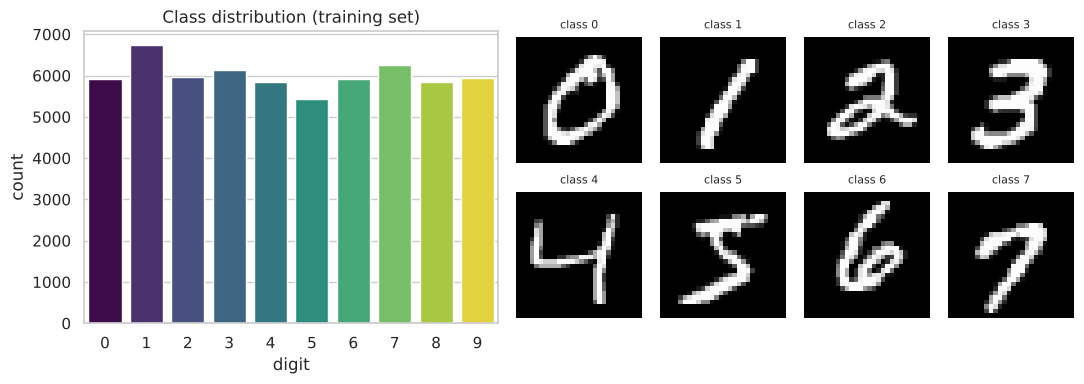

0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949


In [2]:
fig = plt.figure(figsize=(11, 4))
gs = fig.add_gridspec(2, 7)
ax = fig.add_subplot(gs[:, :3])
sns.countplot(x=y_train, ax=ax, hue=y_train, palette="viridis", legend=False)
ax.set_title("Class distribution (training set)"); ax.set_xlabel("digit")
for k in range(8):
    a = fig.add_subplot(gs[k // 4, 3 + k % 4])
    a.imshow(x_train[np.where(y_train == k)[0][0]], cmap="gray"); a.set_title(f"class {k}", fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()
print(pd.Series(y_train).value_counts().sort_index().to_string())

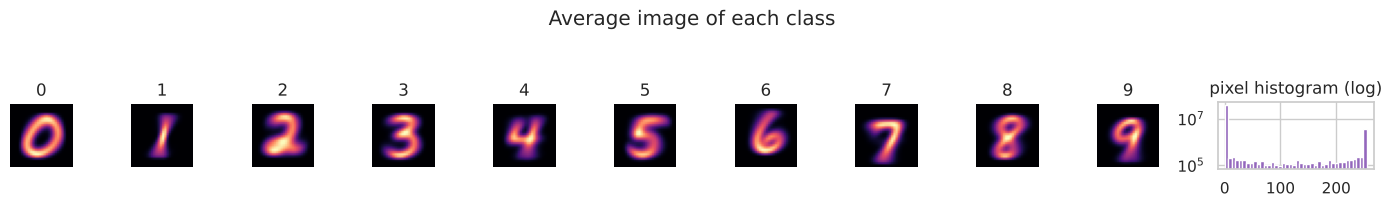

In [3]:
fig, axes = plt.subplots(1, 11, figsize=(14, 1.9), gridspec_kw={"width_ratios": [1] * 10 + [2.5]})
for k in range(10):
    axes[k].imshow(x_train[y_train == k].mean(0), cmap="magma"); axes[k].set_title(str(k)); axes[k].axis("off")
axes[10].hist(x_train.ravel(), bins=40, log=True, color="tab:purple"); axes[10].set_title("pixel histogram (log)")
plt.suptitle("Average image of each class", y=1.08); plt.tight_layout(); plt.show()

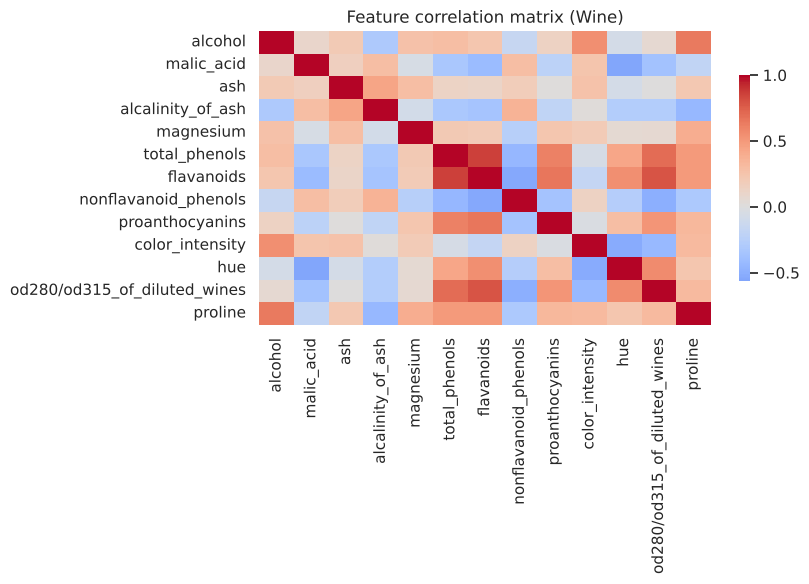

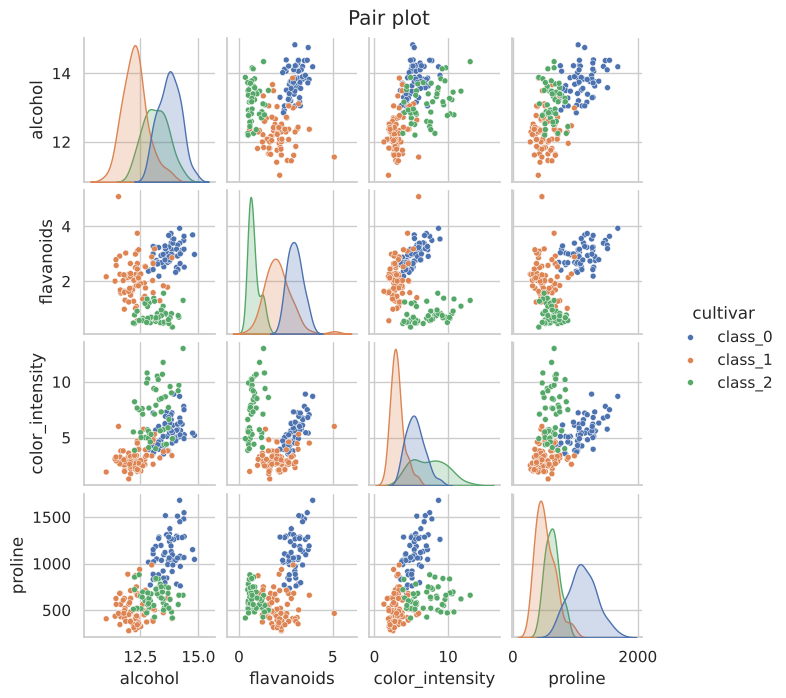

In [4]:
wine = load_wine(as_frame=True)
dfw = wine.frame.copy(); dfw["cultivar"] = wine.target_names[wine.target]
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.heatmap(dfw.drop(columns=["target", "cultivar"]).corr(), cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": .7},
            annot=False)
ax.set_title("Feature correlation matrix (Wine)"); plt.tight_layout(); plt.show()
g = sns.pairplot(dfw[["alcohol", "flavanoids", "color_intensity", "proline", "cultivar"]], hue="cultivar", height=1.7,
                 plot_kws={"s": 18})
g.figure.suptitle("Pair plot", y=1.02); plt.show()

## 2. Dimensionality reduction: seeing high-dimensional data

variance explained by 2 PCs: 17.1%


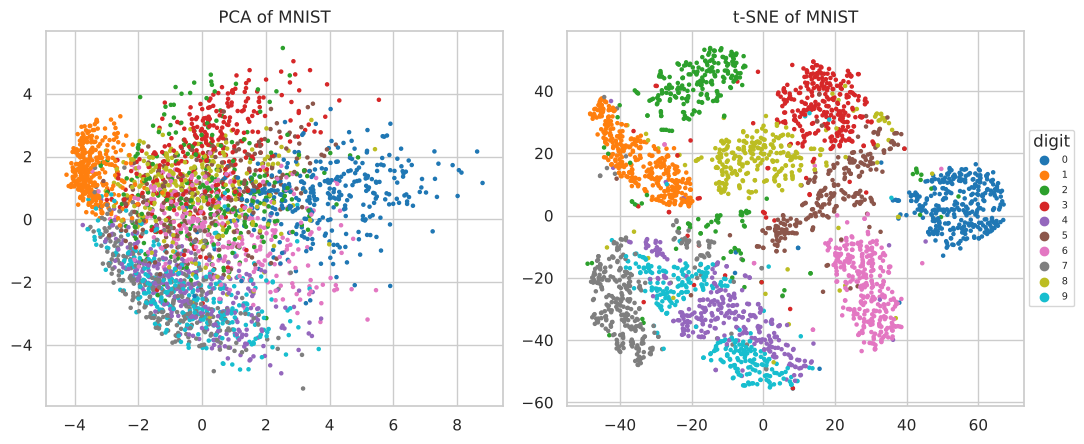

In [5]:
idx = np.random.RandomState(0).choice(len(x_tr), 3000, replace=False)
Xs = x_tr[idx].reshape(3000, -1); ys = y_train[idx]
pca = PCA(n_components=2).fit(Xs); Zp = pca.transform(Xs)
print("variance explained by 2 PCs: %.1f%%" % (100 * pca.explained_variance_ratio_.sum()))
Zt = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(Xs)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, Z, t in zip(ax, [Zp, Zt], ["PCA", "t-SNE"]):
    sc = a.scatter(Z[:, 0], Z[:, 1], c=ys, cmap="tab10", s=5); a.set_title(t + " of MNIST")
ax[1].legend(*sc.legend_elements(), title="digit", fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()

## 3. Monitoring training of a CNN

In [6]:
model = keras.Sequential([
    keras.layers.Input((28, 28, 1)),
    keras.layers.Conv2D(16, 3, activation="relu", name="conv1"),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(32, 3, activation="relu", name="conv2"),
    keras.layers.MaxPooling2D(),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
hist = model.fit(x_tr, y_train, epochs=6, batch_size=128, validation_split=0.1, verbose=2)
loss, acc = model.evaluate(x_te, y_test, verbose=0)
print(f"\nTest accuracy: {acc:.4f}")

Epoch 1/6


422/422 - 7s - 16ms/step - accuracy: 0.9076 - loss: 0.3238 - val_accuracy: 0.9718 - val_loss: 0.0945


Epoch 2/6


422/422 - 5s - 12ms/step - accuracy: 0.9739 - loss: 0.0871 - val_accuracy: 0.9837 - val_loss: 0.0609


Epoch 3/6


422/422 - 6s - 15ms/step - accuracy: 0.9808 - loss: 0.0617 - val_accuracy: 0.9887 - val_loss: 0.0481


... (3 outputs left out)

422/422 - 5s - 13ms/step - accuracy: 0.9879 - loss: 0.0397 - val_accuracy: 0.9882 - val_loss: 0.0444


Epoch 6/6


422/422 - 5s - 13ms/step - accuracy: 0.9902 - loss: 0.0331 - val_accuracy: 0.9887 - val_loss: 0.0441



Test accuracy: 0.9865


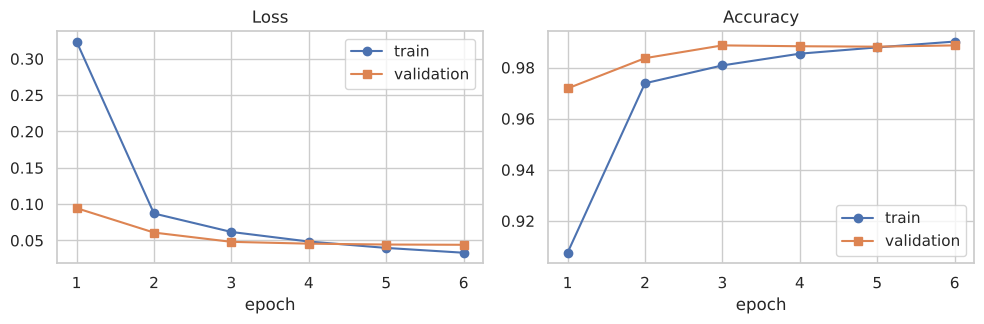

In [7]:
h = pd.DataFrame(hist.history); h["epoch"] = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(h.epoch, h.loss, "o-", label="train"); ax[0].plot(h.epoch, h.val_loss, "s-", label="validation")
ax[0].set(title="Loss", xlabel="epoch"); ax[0].legend()
ax[1].plot(h.epoch, h.accuracy, "o-", label="train"); ax[1].plot(h.epoch, h.val_accuracy, "s-", label="validation")
ax[1].set(title="Accuracy", xlabel="epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. Evaluating predictions

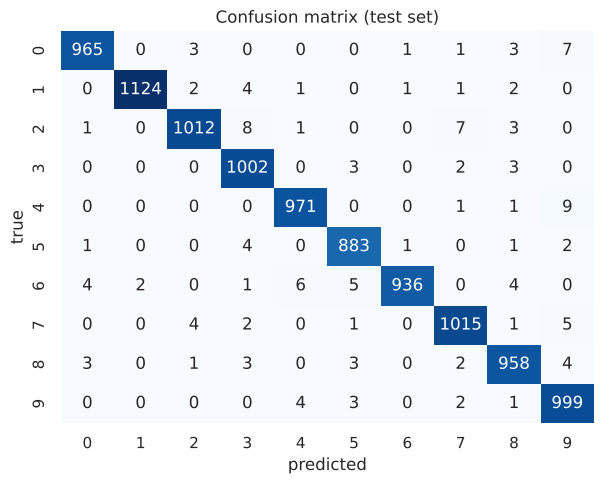

              precision    recall  f1-score   support

           0      0.991     0.985     0.988       980
           1      0.998     0.990     0.994      1135
           2      0.990     0.981     0.985      1032
           3      0.979     0.992     0.985      1010
           4      0.988     0.989     0.988       982
           5      0.983     0.990     0.987       892
           6      0.997     0.977     0.987       958
           7      0.984     0.987     0.986      1028
           8      0.981     0.984     0.982       974
           9      0.974     0.990     0.982      1009

    accuracy                          0.987     10000
   macro avg      0.986     0.986     0.986     10000
weighted avg      0.987     0.987     0.987     10000



In [8]:
probs = model.predict(x_te, verbose=0); pred = probs.argmax(1)
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(title="Confusion matrix (test set)", xlabel="predicted", ylabel="true"); plt.tight_layout(); plt.show()
print(classification_report(y_test, pred, digits=3))

misclassified: 135 of 10000


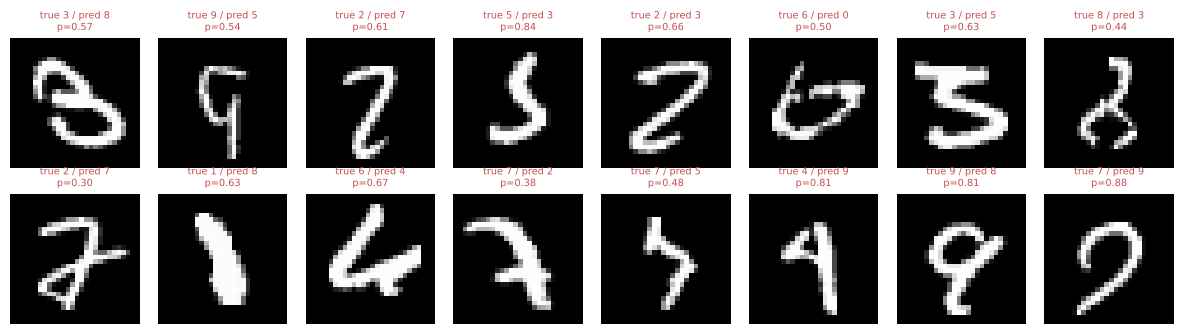

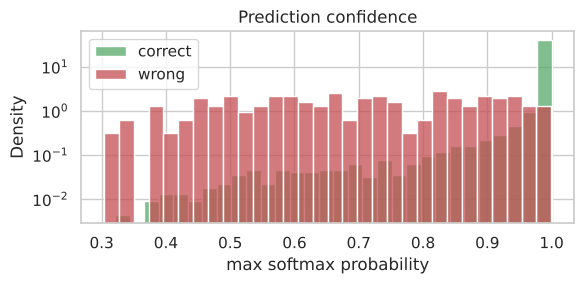

In [9]:
wrong = np.where(pred != y_test)[0]
print("misclassified:", len(wrong), "of", len(y_test))
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for a, i in zip(axes.ravel(), wrong[:16]):
    a.imshow(x_test[i], cmap="gray"); a.set_title(f"true {y_test[i]} / pred {pred[i]}\np={probs[i].max():.2f}", fontsize=7, color="r")
    a.axis("off")
plt.tight_layout(); plt.show()
conf = probs.max(1)
fig, ax = plt.subplots(figsize=(6, 3))
sns.histplot(conf[pred == y_test], bins=30, color="g", label="correct", ax=ax, stat="density")
sns.histplot(conf[pred != y_test], bins=30, color="r", label="wrong", ax=ax, stat="density")
ax.set(title="Prediction confidence", xlabel="max softmax probability"); ax.legend(); ax.set_yscale("log")
plt.tight_layout(); plt.show()

## 5. Looking inside the network

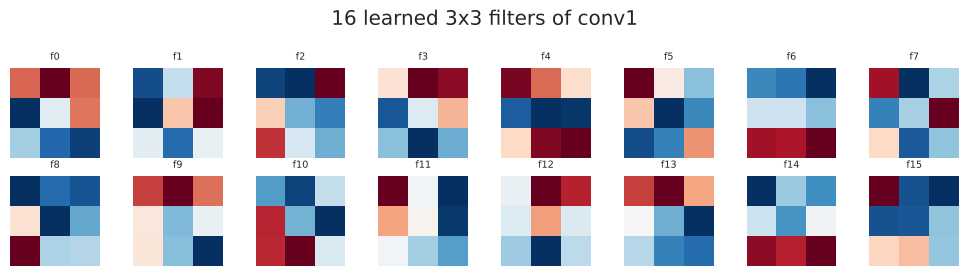

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 28, 28, 1))
  warnings.warn(msg)


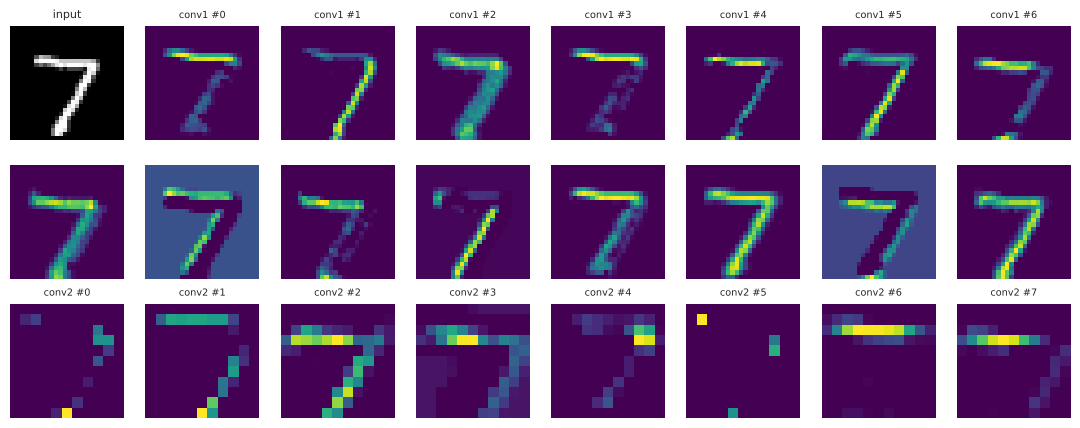

In [10]:
filters = model.get_layer("conv1").get_weights()[0]   # (3,3,1,16)
fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for k, a in enumerate(axes.ravel()):
    a.imshow(filters[:, :, 0, k], cmap="RdBu"); a.axis("off"); a.set_title(f"f{k}", fontsize=7)
plt.suptitle("16 learned 3x3 filters of conv1"); plt.tight_layout(); plt.show()
probe = keras.Model(model.inputs, [model.get_layer("conv1").output, model.get_layer("conv2").output])
f1, f2 = probe(x_te[:1])
fig, axes = plt.subplots(3, 8, figsize=(11, 4.4))
axes[0, 0].imshow(x_te[0, ..., 0], cmap="gray"); axes[0, 0].set_title("input", fontsize=8)
for a in axes.ravel(): a.axis("off")
for k in range(7): axes[0, k + 1].imshow(f1[0, ..., k], cmap="viridis"); axes[0, k + 1].set_title(f"conv1 #{k}", fontsize=7)
for k in range(8): axes[1, k].imshow(f1[0, ..., 8 + k], cmap="viridis")
for k in range(8): axes[2, k].imshow(f2[0, ..., k], cmap="viridis"); axes[2, k].set_title(f"conv2 #{k}", fontsize=7)
plt.tight_layout(); plt.show()

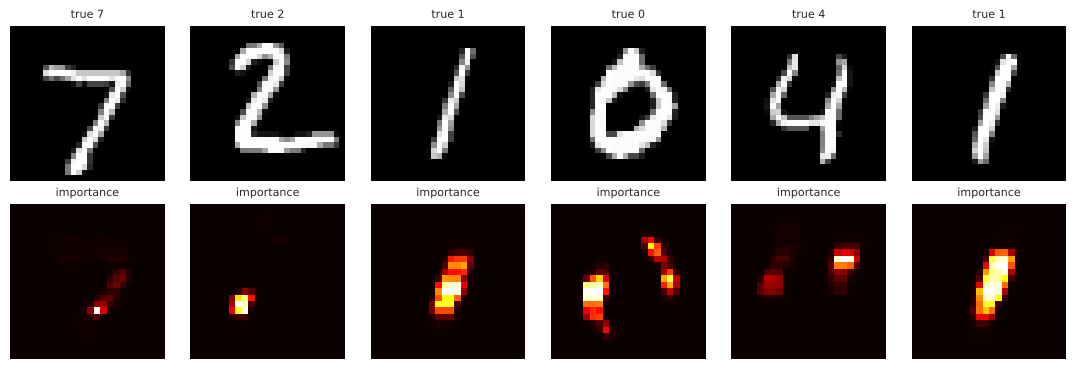

In [11]:
def occlusion_map(img, label, size=5):
    base = model(img[None], training=False).numpy()[0, label]
    heat = np.zeros((28 - size + 1, 28 - size + 1))
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            im = img.copy(); im[i:i + size, j:j + size] = 0
            heat[i, j] = base - model(im[None], training=False).numpy()[0, label]
    return heat
fig, axes = plt.subplots(2, 6, figsize=(11, 3.8))
for c, i in enumerate(range(6)):
    axes[0, c].imshow(x_te[i, ..., 0], cmap="gray"); axes[0, c].set_title(f"true {y_test[i]}", fontsize=8)
    axes[1, c].imshow(occlusion_map(x_te[i], y_test[i]), cmap="hot"); axes[1, c].set_title("importance", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

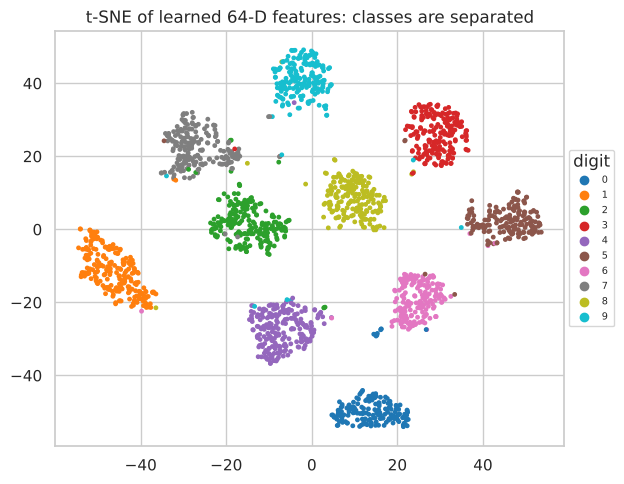

In [12]:
feat_model = keras.Model(model.inputs, model.layers[-2].output)
F = feat_model.predict(x_te[:2000], verbose=0)
Zf = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(F)
fig, ax = plt.subplots(figsize=(6.4, 5))
sc = ax.scatter(Zf[:, 0], Zf[:, 1], c=y_test[:2000], cmap="tab10", s=6)
ax.legend(*sc.legend_elements(), title="digit", fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("t-SNE of learned 64-D features: classes are separated"); plt.tight_layout(); plt.show()